# Lab 04-09 · Waves and Optics Basics

Companion to chapter [04-09](../../chapters/04-09-waves-and-optics.md). Handout: [README.md](README.md). The ngspice netlist [quarter_wave_stub.cir](quarter_wave_stub.cir) simulates Example 04-09.4; run it with `python tools/run_spice.py 04-09` from the repository root.

Cells marked **🔮 Predict** ask for a prediction *before* running. Nothing here is random.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import j1
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — Beats and standing waves from travelling waves

**🔮 Predict:** two counter-propagating waves of equal amplitude: where are the nodes, and do they move?

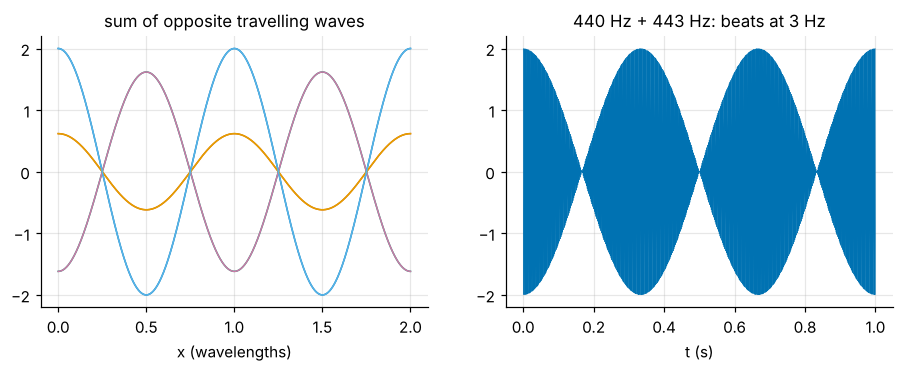

nodes at x = 0.25, 0.75, 1.25, 1.75 wavelengths; values there: [0.0, 0.0, 0.0, 0.0]


In [2]:
x = np.linspace(0, 2, 800); t = np.linspace(0, 1, 6)
k, w = 2 * np.pi, 2 * np.pi
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for tt in t:
    axes[0].plot(x, np.cos(k * x - w * tt) + np.cos(k * x + w * tt), lw=1)
axes[0].set_title("sum of opposite travelling waves"); axes[0].set_xlabel("x (wavelengths)")
tt = np.linspace(0, 1, 20000)
s = np.cos(2 * np.pi * 440 * tt) + np.cos(2 * np.pi * 443 * tt)
axes[1].plot(tt, s, lw=0.3); axes[1].set_title("440 Hz + 443 Hz: beats at 3 Hz"); axes[1].set_xlabel("t (s)")
plt.show()
print("nodes at x = 0.25, 0.75, 1.25, 1.75 wavelengths; values there:", [round(abs(2*math.cos(k*xx)), 12) for xx in (0.25, 0.75, 1.25, 1.75)])

The sum is $2\cos(kx)\cos(\omega t)$: nodes a quarter-wavelength from each crest, fixed in place.

## Part 2 — A phased array

The array factor of $N$ isotropic elements spaced $d$, with a progressive phase Δφ, is $AF(\theta) = \big|\sum_{m=0}^{N-1}e^{jm(kd\sin\theta - \Delta\varphi)}\big|$.

**🔮 Predict:** for 8 elements at λ/2, the beam's width at broadside and when steered to 30°. What happens at a full-wavelength spacing?

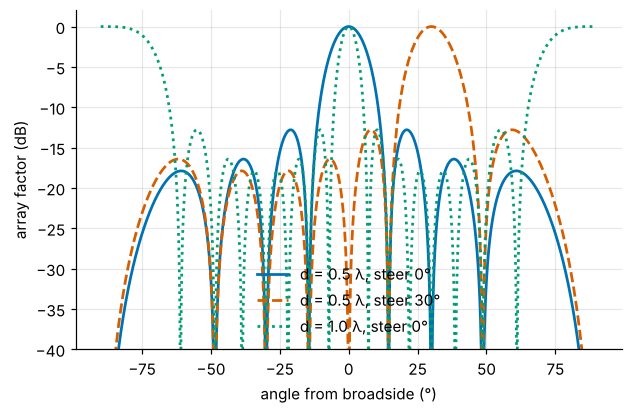

-3 dB beamwidth, 8 elements at lambda/2: broadside 12.80 deg; steered to 30 deg 14.84 deg


In [3]:
def af(theta, N, d_over_lam, dphi):
    m = np.arange(N)[:, None]
    return np.abs(np.exp(1j * m * (2 * np.pi * d_over_lam * np.sin(theta) - dphi)).sum(axis=0)) / N
def beamwidth_deg(N, d_over_lam, steer_deg):
    dphi = 2 * np.pi * d_over_lam * math.sin(math.radians(steer_deg))
    f = lambda th: af(np.array([th]), N, d_over_lam, dphi)[0] - 1 / math.sqrt(2)
    t0 = math.radians(steer_deg)
    lo = brentq(f, t0 - 0.5, t0); hi = brentq(f, t0, t0 + 0.5)
    return math.degrees(hi - lo)
th = np.linspace(-np.pi / 2, np.pi / 2, 4001)
for d, steer, ls in ((0.5, 0, "-"), (0.5, 30, "--"), (1.0, 0, ":")):
    plt.plot(np.degrees(th), 20 * np.log10(af(th, 8, d, 2*np.pi*d*math.sin(math.radians(steer))) + 1e-6), ls, label=f"d = {d} λ, steer {steer}°")
plt.ylim(-40, 2); plt.xlabel("angle from broadside (°)"); plt.ylabel("array factor (dB)"); plt.legend(); plt.show()
print(f"-3 dB beamwidth, 8 elements at lambda/2: broadside {beamwidth_deg(8, 0.5, 0):.2f} deg; steered to 30 deg {beamwidth_deg(8, 0.5, 30):.2f} deg")

Steering widens the beam (the array looks shorter from an angle, by about $1/\cos\theta$), and at a full-wavelength spacing extra beams of full strength appear at ±90°: grating lobes.

## Part 3 — Diffraction by brute force

Sum Huygens wavelets across a slit of width $a = 10\lambda$ (far field), and across a circular aperture, and find the first zeros.

**🔮 Predict:** the first zero of each, in units of λ/a (or λ/D).

In [4]:
lam, a = 1.0, 10.0
ys = np.linspace(-a / 2, a / 2, 4001)
def slit_amp(s):          # s = sin(theta); the symmetric slit's wavelet sum is real: sum of cos(k y s)
    return np.trapezoid(np.cos(2 * np.pi / lam * ys * s), ys) / a
s1 = brentq(slit_amp, 0.05, 0.15)
print(f"slit: first zero at sin(theta) = {s1:.5f} = {s1*a/lam:.4f} lambda/a")
D = 10.0
rr = np.linspace(0, D / 2, 801); ph = np.linspace(0, 2 * np.pi, 361)
R, PH = np.meshgrid(rr, ph)
def circ_amp(s):          # wavelets from the disk, weighted by area r dr dphi
    return np.trapezoid(np.trapezoid(np.cos(2 * np.pi / lam * R * np.cos(PH) * s) * R, rr, axis=1), ph)
s2 = brentq(circ_amp, 0.10, 0.14)
print(f"circle: first zero at sin(theta) = {s2:.5f} = {s2*D/lam:.4f} lambda/D  (Bessel root 3.8317/pi = {3.8317059702/math.pi:.4f})")

slit: first zero at sin(theta) = 0.10000 = 1.0000 lambda/a
circle: first zero at sin(theta) = 0.12197 = 1.2197 lambda/D  (Bessel root 3.8317/pi = 1.2197)


Adding up wavelets reproduces $\lambda/a$ and $1.22\lambda/D$: the Rayleigh factor 1.22 is just the first zero of the Bessel function $J_1$ divided by π.

## Part 4 — A thin-film coating, by characteristic matrices

Each layer is a 2×2 matrix; multiplying them gives any stack's reflectance (the optical cousin of the ABCD matrices of cascaded two-ports).

**🔮 Predict:** where is the MgF₂ coating's reflectance lowest, and what is it there?

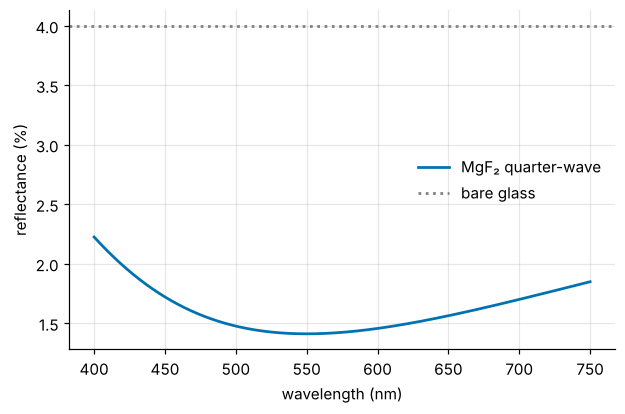

minimum 1.411 % at 550.0 nm; at 450 nm 1.721 %, at 650 nm 1.563 %


In [5]:
def reflectance(lam_nm, layers, n0=1.0, ns=1.5):
    M = np.eye(2, dtype=complex)
    for n, d in layers:
        dl = 2 * np.pi * n * d / lam_nm
        M = M @ np.array([[np.cos(dl), 1j * np.sin(dl) / n], [1j * n * np.sin(dl), np.cos(dl)]])
    B, Cc = M @ np.array([1, ns])
    r = (n0 * B - Cc) / (n0 * B + Cc)
    return abs(r) ** 2
lams = np.linspace(400, 750, 701)
mgf2 = [(1.38, 550 / (4 * 1.38))]
R = np.array([reflectance(l, mgf2) for l in lams])
plt.plot(lams, R * 100, label="MgF₂ quarter-wave"); plt.axhline(4, ls=":", color="0.5", label="bare glass")
plt.xlabel("wavelength (nm)"); plt.ylabel("reflectance (%)"); plt.legend(); plt.show()
print(f"minimum {R.min()*100:.3f} % at {lams[R.argmin()]:.1f} nm; at 450 nm {reflectance(450, mgf2)*100:.3f} %, at 650 nm {reflectance(650, mgf2)*100:.3f} %")

## Part 5 — Fiber acceptance and dispersion

First, which rays does a fiber accept? A ray entering from air at angle θ refracts to θ₁ in the core (Snell), then meets the core–cladding wall at 90° − θ₁; it is trapped only if that exceeds the critical angle.

**🔮 Predict:** the acceptance half-angle of a fiber with core 1.468 and cladding 1.463, and how much a 0.1 nm-wide source's pulse spreads over 10 km and 100 km at 17 ps/(nm·km).

In [6]:
n1, n2 = 1.468, 1.463
theta_c = math.asin(n2 / n1)                      # critical angle at the core-cladding wall
def trapped(theta_air):
    theta1 = math.asin(math.sin(theta_air) / n1)  # refraction into the core
    return (math.pi / 2 - theta1) >= theta_c
angles = np.linspace(0, math.radians(20), 200001)
accept = max(a for a in angles if trapped(a))
print(f"acceptance half-angle by ray tracing: {math.degrees(accept):.3f} deg; NA formula asin(sqrt(n1^2 - n2^2)): {math.degrees(math.asin(math.sqrt(n1**2 - n2**2))):.3f} deg")
for L in (2, 10, 40, 100):
    print(f"{L:4d} km: spreading {17*L*0.1:.1f} ps; maximum bit rate at half-a-bit spreading {1/(2*17*L*0.1e-12)/1e9:.1f} Gb/s")

acceptance half-angle by ray tracing: 6.953 deg; NA formula asin(sqrt(n1^2 - n2^2)): 6.953 deg
   2 km: spreading 3.4 ps; maximum bit rate at half-a-bit spreading 147.1 Gb/s
  10 km: spreading 17.0 ps; maximum bit rate at half-a-bit spreading 29.4 Gb/s
  40 km: spreading 68.0 ps; maximum bit rate at half-a-bit spreading 7.4 Gb/s
 100 km: spreading 170.0 ps; maximum bit rate at half-a-bit spreading 2.9 Gb/s


## Your turn

1. In Part 2, taper the element amplitudes (for example a raised-cosine window). What happens to the sidelobes and the beamwidth? (This is the same trade as windowing in spectral analysis, Course 16.)
2. In Part 4, design a two-layer coating (MgF₂ on top of a high-index layer) and compare its bandwidth with the single layer.